# Lesson 2 - Exploratory data analysis

> A walkthrough on the fundamental mechanics to manipulate the data contained in pandas Series or DataFrame objects.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Learning objectives

* Understand the main steps involved in exploratory data analysis
* Visualise geographical data with seaborn
* Slice, mask, and index `pandas.Series` and `pandas.DataFrame` objects
* Merge `pandas.DataFrame` objects together on a common key
* Apply the `DataFrame.groupby()` operation to aggregate data across different groups of interest

## References

This lesson draws heavily on the following textbook chapters:

* Chapter 2 of _Hands-On Machine Learning with Scikit-Learn and TensorFlow_ by Aurèlien Geron
* Chapter 3 (pp. 146-170) of _Python Data Science Handbook_ by Jake Vanderplas

You may also find the following blog post useful:

* [Exploratory Data Analysis of Craft Beers: Data Profiling](https://www.datacamp.com/community/tutorials/python-data-profiling)

## What is exploratory data analysis?

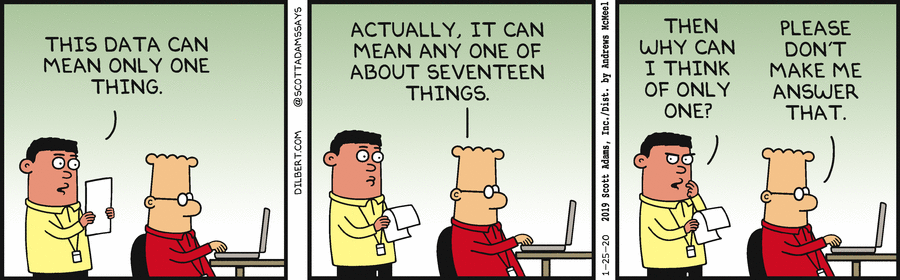

In data science we apply the scientific method to data with the goal gain insights. This means that we state a hypothesis about the data, test it and refine it if necessary. In this framework, exploratory data analysis (EDA) is the step where we explore the data before actually building models. This helps us understand what information is actually contained in the data and what insights could be gained from it.

Formally, the goals of EDA are:

- Suggest hypotheses about the phenomena of interest
- Check if necessary data is available to test these hypotheses
- Make a selection of appropriate methods and models to achieve the goal
- Suggest what data should be gathered for further investigation

This exploratory phase lays out the path for the rest of a data science project and is therefore a crucial part of the process.

## Linking our Work to the Data Analytics Lifecycle

Throughout this module, we will use the CRISP-DM (Cross Industry Standard Process for Data Mining) model as our main framework. Each exercise you complete is not just a coding task, but also part of the larger data analytics lifecycle:

* Business Understanding: what question are we trying to answer?

* Data Understanding: exploring the raw dataset to see what it contains.

* Data Preparation: cleaning, filtering, and transforming the data for analysis.

* Modelling: applying techniques to discover patterns and relationships.

* Evaluation: assessing whether the patterns are meaningful.

* Deployment: communicating or implementing results.

You may also hear of the older KDD (Knowledge Discovery in Databases) process, which shares similar stages (selection, preprocessing, transformation, data mining, interpretation). We will emphasise CRISP-DM because it is more widely used in practice, and it will form the basis for your assignment.

## The data

In this lesson we will analyse two datasets:

* `housing.csv`
* `housing_addresses.csv`

The first is the [California housing dataset](https://www.kaggle.com/camnugent/california-housing-prices) we saw in lesson 1, while the second provides information about the neighbourhoods associated with each house. This auxiliary data was generated using the [reverse geocoding](https://en.wikipedia.org/wiki/Reverse_geocoding) functionality from [Google Maps](https://developers.google.com/maps/documentation/geocoding/intro#ReverseGeocoding), where the latitude and longitude coordinates for each house are converted into the closest, human-readable address.

The type of questions we will try to find answers to include:

* Which cities have the most houses?
* Which cities have the most expensive houses?
* What is the breakdown of the house prices by proximity to the ocean?

## Import libraries

As in lesson 1, we will be making use of the pandas and seaborn libraries. It is often a good idea to import all your libraries in a single cell block near the top of your notebooks so that your collaborators can quickly see whether they need to install new libraries or not.

In [ ]:
# render plots in notebook
%matplotlib inline

In [ ]:
# data wrangling
import pandas as pd
import numpy as np
from pathlib import Path

# data viz
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# these commands define the color scheme
sns.set(color_codes=True)
sns.set_palette(sns.color_palette('muted'))

## Load the data

As usual, we start by uploading our datasets and supporting files'housing.csv' california.png'and 'housing_addresses.csv' which are available from the Canvas folder.

We also make use of the `pathlib` library to handle our filepaths: This is optional but it makes life a little easier.

In [ ]:
DATA = Path('../content') # you may need to change this location depending on where you uploaed your files to
!ls {DATA}

drive  sample_data


In [ ]:
DATA = Path('/content/drive/MyDrive')
housing_data = pd.read_csv(DATA/'housing (2).csv'); housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
housing_addresses = pd.read_csv(DATA/'housing_addresses.csv'); housing_addresses.head()

,street_number,route,locality-political,postal_code,latitude_longitude
0,3130,Grizzly Peak Boulevard,Berkeley,94705.0,"37.88,-122.23"
1,2005,Tunnel Road,Oakland,94611.0,"37.86,-122.22"
2,6886,Chabot Road,Oakland,94618.0,"37.85,-122.24"
3,6365,Florio Street,Oakland,94618.0,"37.85,-122.25"
4,5407,Bryant Avenue,Oakland,94618.0,"37.84,-122.25"


## Inspect the data

### The shape of data

Whenever we have a new dataset it is handy to begin by getting an idea of how large the `DataFrame` is. This can be done with either the `len` or `DataFrame.shape` methods:

In [ ]:
# get number of rows
len(housing_data), len(housing_addresses)

(20640, 12590)

In [ ]:
# get tuples of (n_rows, n_columns)
housing_data.shape, housing_addresses.shape

((20640, 10), (12590, 5))

### Rename columns

Usually one finds that the column headers in the raw data are either ambiguous or appear in multiple `DataFrame` objects, in which case it is handy to give them the same name. Although it's obvious from the `DataFrame.head()` method what the column headers are for our housing and address data, in most cases one has tens or hundreds of columns and the fastest way to see their names is as follows:

In [ ]:
housing_addresses.columns

Index(['street_number', 'route', 'locality-political', 'postal_code',
       'latitude_longitude'],
      dtype='object')

Let's rename the `route` and `locality-political` columns to something more transparent:

In [ ]:
housing_addresses.rename(columns={'route':'street_name', 'locality-political':'city'}, inplace=True)

In [ ]:
# check that the renaming worked
housing_addresses.head()

,street_number,street_name,city,postal_code,latitude_longitude
0,3130,Grizzly Peak Boulevard,Berkeley,94705.0,"37.88,-122.23"
1,2005,Tunnel Road,Oakland,94611.0,"37.86,-122.22"
2,6886,Chabot Road,Oakland,94618.0,"37.85,-122.24"
3,6365,Florio Street,Oakland,94618.0,"37.85,-122.25"
4,5407,Bryant Avenue,Oakland,94618.0,"37.84,-122.25"


> Note: Many functions like `DataFrame.rename()` can manipulate an object _in-place_ without returning a new object. In other words, when `inplace=True` is passed the data is renamed in place as `data_frame.an_operation(inplace=True)` so we don't need the usual assignment `LHS = RHS`. By default, `inplace=False` so you have to set it explicitly if needed.

### Unique values

Since we are dealing with data about California, we should check that the `city` column contains a reasonable number of unique entries. In pandas we can check this the `DataFrame.nunique()` method:

In [ ]:
housing_addresses['city'].nunique()

989

---

#### Exercise #1 —Series indexing & slicing on housing age
CRISP-DM link: This task belongs to the Data Understanding stage. By slicing and summarising the data, you get familiar with the scale and type of values (e.g., typical housing ages), which is essential before moving to preparation or modelling.

1. Get the first 3 values of housing_median_age.

2. Get the last value in two different ways.

3. Slice rows 100–110 and show the length of the slice.

4. Use .describe() on housing_median_age and print only the mean and std.

---

In [114]:
# 1. Get the first 3 values of housing_median_age.
print('\033[1m' +  "\n1. Get the first 3 values of housing_median_age." + '\033[0m')
print(housing_data['housing_median_age'].head(3))

# 2. Get the last value in two different ways.
print('\033[1m' +  "\n2. Get the last value in two different ways." + '\033[0m')
print(housing_data['housing_median_age'].tail(1).values[0])
print(housing_data['housing_median_age'].iloc[-1])


# 3. Slice rows 100–110 and show the length of the slice.
print('\033[1m' +  "\n3. Slice rows 100–110 and show the length of the slice." + '\033[0m')
slice_data = housing_data.iloc[100:111]
print(len(slice_data))  # 11

# 4. Use .describe() on housing_median_age and print only the mean and std.
print('\033[1m' +  "\n4. Use .describe() on housing_median_age and print only the mean and std." + '\033[0m')

print(housing_data['housing_median_age'].describe()[['mean', 'std']])



1. Get the first 3 values of housing_median_age.
0    41.0
1    21.0
2    52.0
Name: housing_median_age, dtype: float64

2. Get the last value in two different ways.
16.0
16.0

3. Slice rows 100–110 and show the length of the slice.
11

4. Use .describe() on housing_median_age and print only the mean and std.
mean    28.639486
std     12.585558
Name: housing_median_age, dtype: float64


## Visualising geographical data

In this lesson we will be focusing on how the house location affects its price, so let's make a scatterplot of the latitude and longitude values to see if we can identify any interesting patterns:

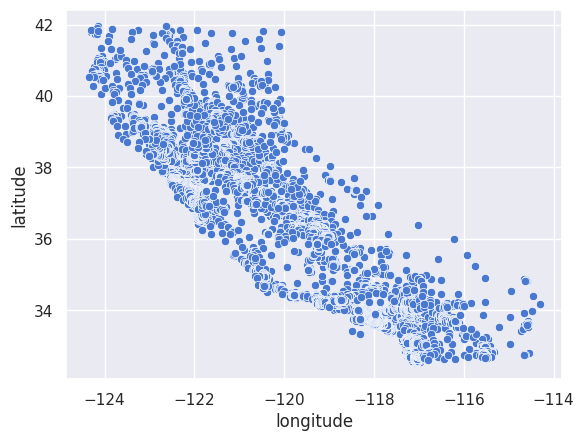

In [ ]:
sns.scatterplot(x="longitude", y="latitude", data=housing_data);

Although the points look like the shape of California, we see that many are overlapping which obscures potentially interesting substructure. We can fix this by configuring the transparency of the points with the `alpha` argument:

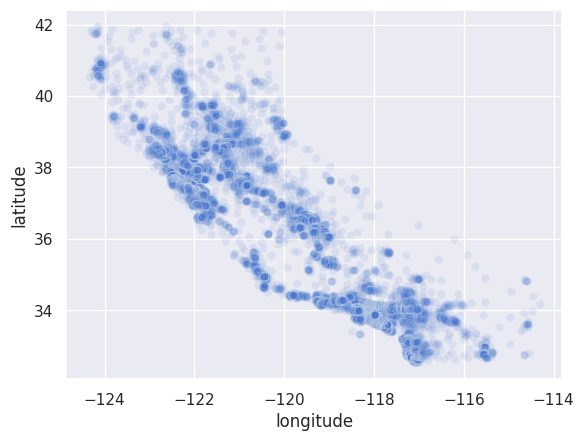

In [ ]:
sns.scatterplot(x="longitude", y="latitude", data=housing_data, alpha=0.1);

This is much better as we can now see distinct clusters of houses. To make this plot even more informative, let's colour the points according to the median house value; we will use the [viridis](https://bids.github.io/colormap/) colourmap (palette) as this has been carefully designed for data that has a sequential nature (i.e. low to high values):

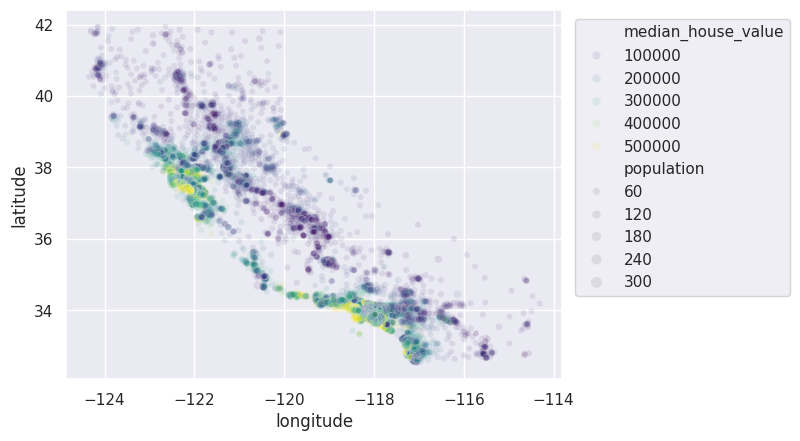

In [ ]:
fig = sns.scatterplot(
    x="longitude",
    y="latitude",
    data=housing_data,
    alpha=0.1,
    hue="median_house_value",
    palette="viridis",
    size=housing_data["population"] / 100
)

# place legend outside of figure
fig.legend(loc="center left", bbox_to_anchor=(1.01, 0.6), ncol=1);

---

#### Exercise #2
CRISP-DM link: This is part of Data Preparation, where we create subsets and masks to focus on relevant ranges (e.g., houses younger than 20 years). Filtering ensures that subsequent analysis targets the right segments of the data.

1. Select rows where housing_median_age is less than 20. Count how many.

2. Select rows where housing_median_age is greater than 50. Count how many.

3. Build a mask for values between 30 and 40 inclusive. Display the first 5 results.

---

In [116]:
print('\033[1m' +  "" + '\033[0m')


# Select rows where housing_median_age is less than 20. Count how many.
print('\033[1m' +  "\nSelect rows where housing_median_age is less than 20. Count how many." + '\033[0m')
print(housing_data[housing_data['housing_median_age'] < 20].shape[0])

# Select rows where housing_median_age is greater than 50. Count how many.
print('\033[1m' +  "\nSelect rows where housing_median_age is greater than 50. Count how many." + '\033[0m')
print(housing_data[housing_data['housing_median_age'] > 50].shape[0])

# Build a mask for values between 30 and 40 inclusive. Display the first 5 results.
print('\033[1m' +  "\nBuild a mask for values between 30 and 40 inclusive. Display the first 5 results." + '\033[0m')
mask = (housing_data['housing_median_age'] >= 30) & (housing_data['housing_median_age'] <= 40)
housing_data[mask].head()



Select rows where housing_median_age is less than 20. Count how many.
5828

Select rows where housing_median_age is greater than 50. Count how many.
1321

Build a mask for values between 30 and 40 inclusive. Display the first 5 results.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,latitude_longitude
20,-122.27,37.85,40.0,751.0,184.0,409.0,166.0,1.3578,147500.0,NEAR BAY,"37.85,-122.27"
48,-122.26,37.82,40.0,624.0,195.0,423.0,160.0,0.9506,187500.0,NEAR BAY,"37.82,-122.26"
49,-122.27,37.82,40.0,946.0,375.0,700.0,352.0,1.7750,112500.0,NEAR BAY,"37.82,-122.27"
76,-122.28,37.81,36.0,2914.0,562.0,1236.0,509.0,2.4464,102100.0,NEAR BAY,"37.81,-122.28"
79,-122.28,37.80,38.0,684.0,176.0,344.0,155.0,2.0114,131300.0,NEAR BAY,"37.8,-122.28"


Finally, to make our visualisation a little more intuitive, we can also overlay the scatter plot on an actual map of California:

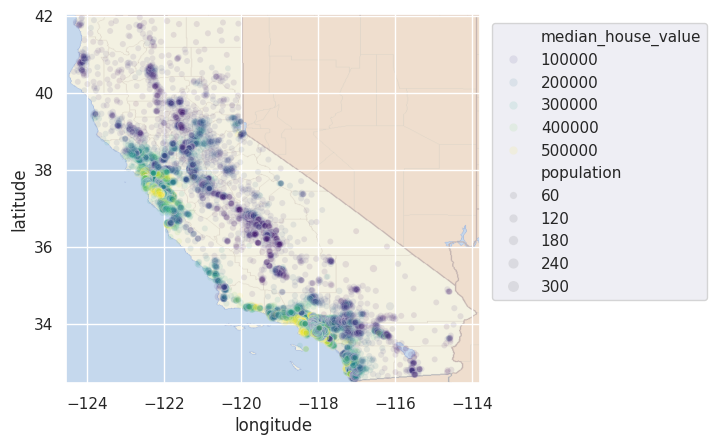

In [ ]:
fig = sns.scatterplot(
    x="longitude",
    y="latitude",
    data=housing_data,
    alpha=0.1,
    hue="median_house_value",
    palette="viridis",
    size=housing_data["population"] / 100
)

# place legend outside of figure
fig.legend(loc="center left", bbox_to_anchor=(1.01, 0.6), ncol=1);

# ref - www.kaggle.com/camnugent/geospatial-feature-engineering-and-visualization/
california_img=mpimg.imread(DATA/'california.png')
plt.imshow(california_img, extent=[-124.55, -113.80, 32.45, 42.05], alpha=0.5);

## Merging DataFrames

Although the `housing_data` and `housing_addresses` `DataFrames` contain interesting information, it would be nice if there was a way to join the two tables.

More generally, one of the most common operations in pandas (or data science for that matter) is the combination of data contained in various objects. In particular, _**merge**_ or _**join**_ operations combine datasets by linking rows using one of more _**keys**_. These operations are central to relational databases (e.g. SQL-based). The `pandas.merge()` function in pandas is the main entry point for using these algorithms on your data.

Let's use this idea to combine the `housing_data` and `housing_addresses` `pandas.DataFrame` objects via their common latitude and longitude coordinates. First we need to combine the `latitude` and `longitude` columns of `housing_data` into the same `lat,lon` format as our `housing_addresses` `pandas.DataFrame`. To do so, we will use the `Series.astype()` function to convert the numerical column values to strings, then use string concatenation to create a new `latitude_longitude` column with the desired format:

In [ ]:
# create new column
housing_data['latitude_longitude'] = housing_data['latitude'].astype(str) + ',' + housing_data['longitude'].astype(str)
# check the column was created
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,latitude_longitude
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,"37.88,-122.23"
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,"37.86,-122.22"
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,"37.85,-122.24"
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,"37.85,-122.25"
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,"37.85,-122.25"


Now that we have `latitude_longitude` present in both `pandas.DataFrame` objects we can merge the two tables together in pandas as follows:

In [ ]:
# create a new DataFrame from the merge
housing_merged = pd.merge(
    housing_data, housing_addresses, how="left", on="latitude_longitude"
)
# check merge worked
housing_merged.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,latitude_longitude,street_number,street_name,city,postal_code
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,"37.88,-122.23",3130,Grizzly Peak Boulevard,Berkeley,94705.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,"37.86,-122.22",2005,Tunnel Road,Oakland,94611.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,"37.85,-122.24",6886,Chabot Road,Oakland,94618.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,"37.85,-122.25",6365,Florio Street,Oakland,94618.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,"37.85,-122.25",6365,Florio Street,Oakland,94618.0


Boom! We now have a single `pandas.DataFrame` that links information for house prices and attributes and their addresses.

> Note: The merge operation above is an example of a _left join_, namely we use all the key combinations of `latitude_longitude` found in the left table `housing_data`.

In general the `'how'` argument of `pandas.merge()` allows four different join types:
* `'left'`: Use all key combinations found in the left table
* `'right'`: Use all key combinations found in the right table
* `'inner'`: Use only the key combinations observed in both tables
* `'outer'`: Use all key combinations observed in both tables together

A visual example of these different merges in action is shown in the figure below.

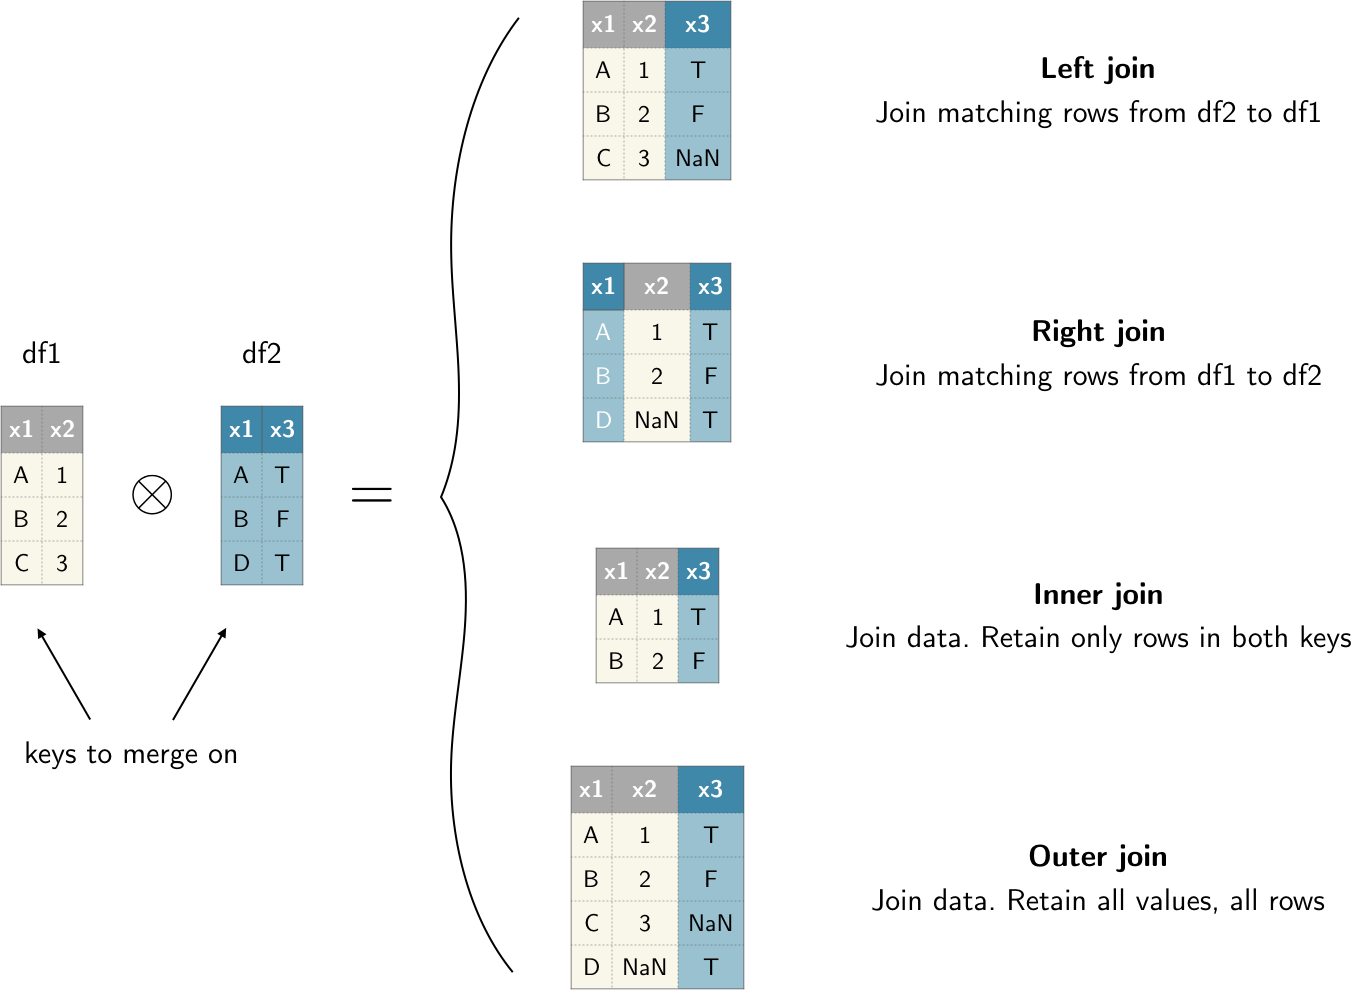 <b>Figure:</b> Graphical representation of the different types of merges between two DataFrames df1 and df2 that are possible in pandas. </p>

> Warning: If the keys in one table match more than one row in the other `pandas.DataFrame` you can expect a _larger_ table to appear after you do a left join. To avoid this behaviour, you can run `DataFrame.drop_duplicates()` before doing the merge.

In [ ]:
# 1
loc_sel = housing_merged.loc[2, ['city','population']]

# 2
iloc_sel = housing_merged.iloc[2, [3, 11]]

# 3
def pick(df, row_idx, cols):
    return df.loc[row_idx, cols]

pick(housing_merged, 2, ['city','population'])


,2
city,Oakland
population,496.0


## Dropping columns

It is not uncommon for a dataset to have tens or hundreds of columns, and in practice we may only want to focus our attention on a smaller subset. One way to remove unwanted columns is via the `DataFrame.drop()` method. Since we have duplicate information about the latitude and longitude coordinate, we may as well drop the `latitude_longitude` column from our merged `pandas.DataFrame`:

In [ ]:
# inplace=True manipulates an object without returning a new object
housing_merged.drop(['latitude_longitude'], axis=1, inplace=True); housing_merged.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,3130,Grizzly Peak Boulevard,Berkeley,94705.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,2005,Tunnel Road,Oakland,94611.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,6886,Chabot Road,Oakland,94618.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,6365,Florio Street,Oakland,94618.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6365,Florio Street,Oakland,94618.0


> Note: You will often encounter the cryptic axis parameter when dealing with `pandas.DataFrame` and `pandas.Series` objects. This parameter is used to specify along which dimension we want to apply a given transformation - see the figure below for a graphical representation.

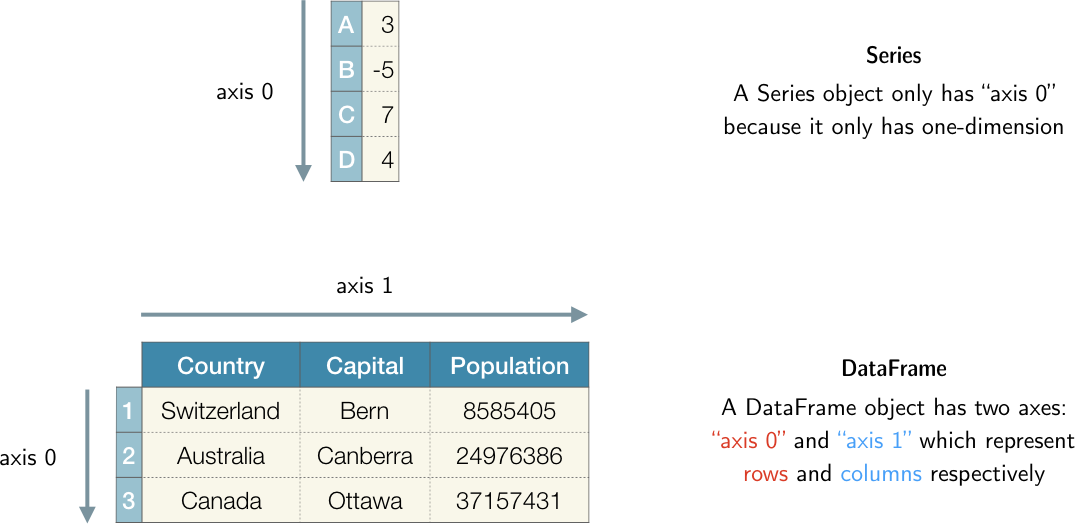
<b>Figure:</b> Visualisation of the <code>axis</code> parameter in pandas. </p>

## Saving a DataFrame to disk

At this point, we have a unfified table with housing data and their addresses. This is usually a good point to save the intermediate results to disk so that we can reload them without having to run all preprocessing steps. To do so in pandas, we can make use of the `DataFrame.to_csv()` function:

In [ ]:
# use index=False to avoid adding an extra column for the index
housing_merged.to_csv(path_or_buf=DATA/'housing_merged.csv', index=False)

---

#### Exercise #3
CRISP-DM link: This activity supports Data Understanding and Preparation. Being able to select rows and columns accurately is a core step before conducting aggregations or modelling. It also builds confidence in handling multi-attribute datasets.

1. Using .loc, select the row with index label 2 and the columns ['city', 'population'].

2. Using .iloc, select the 3rd row and the 4th and 12th columns (check your dataset shape).

3. Write a small function that takes a DataFrame, a row index, and a list of columns, and returns just those

---

In [119]:
# Using .loc, select the row with index label 2 and the columns ['city', 'population'].
print('\033[1m' +  "\nUsing .loc, select the row with index label 2 and the columns ['city', 'population']." + '\033[0m')
loc_selection = housing_merged.loc[2, ['city', 'population']]
print(loc_selection)

# Using .iloc, select the 3rd row and the 4th and 12th columns (check your dataset shape).
# 3rd row is index 2
# Columns are 'total_rooms' (index 3) and 'street_name' (index 11)
print('\033[1m' +  "\nUsing .iloc, select the 3rd row and the 4th and 12th columns (check your dataset shape)." + '\033[0m')
iloc_selection = housing_merged.iloc[2, [3, 11]]
print(iloc_selection)

# Write a small function that takes a DataFrame, a row index, and a list of columns, and returns just those
print('\033[1m' +  "\nWrite a small function that takes a DataFrame, a row index, and a list of columns, and returns just those." + '\033[0m')
def pick_data(dataFrame, row_index, columns):
    return dataFrame.loc[row_index, columns]

# Example usage of the function:
function_selection = pick_data(housing_merged, 2, ['city', 'population'])
print(function_selection)



Using .loc, select the row with index label 2 and the columns ['city', 'population'].
city          Oakland
population      496.0
Name: 2, dtype: object

Using .iloc, select the 3rd row and the 4th and 12th columns (check your dataset shape).
total_rooms         1467.0
street_name    Chabot Road
Name: 2, dtype: object

Write a small function that takes a DataFrame, a row index, and a list of columns, and returns just those.
city          Oakland
population      496.0
Name: 2, dtype: object


## Indexing, selection, and filtering

Now that we have a tidy `pandas.DataFrame` let's apply some of the most common pandas methods to make queries on the data.

### Series

A `pandas.Series` object provides array-style item selection that allows one to perform _slicing, masking,_ and _fancy indexing_. For example, we can study the `housing_median_age` colum from a variety of angles:

In [ ]:
# define a new Series object
age = housing_merged['housing_median_age']

In [ ]:
age

,housing_median_age
0,41.0
1,21.0
2,52.0
3,52.0
4,52.0
...,...
20635,25.0
20636,18.0
20637,17.0
20638,18.0


In [ ]:
# get first entry
age[0]

np.float64(41.0)

In [ ]:
# slicing by index
age[2:5]

,housing_median_age
2,52.0
3,52.0
4,52.0


In [ ]:
# slice and just get values
age[2:5].values

array([52., 52., 52.])

In [ ]:
age.describe()

,housing_median_age
count,20640.000000
mean,28.639486
std,12.585558
min,1.000000
25%,18.000000
50%,29.000000
75%,37.000000
max,52.000000


In [ ]:
# masking (filtering)
age[(age > 10.0) & (age < 20.0)]

,housing_median_age
75,17.0
77,19.0
80,17.0
90,16.0
131,18.0
...,...
20632,15.0
20636,18.0
20637,17.0
20638,18.0


In [ ]:
# fancy indexing
age[[0, 4]]

,housing_median_age
0,41.0
4,52.0


### DataFrame

Since a `pandas.DataFrame` acts like a two-dimensional array, pandas provides special indexing operators called `DataFrame.iloc[]` and `DataFrame.loc[]` to slice and dice our data. As an example, let's select a single row and multiple columns by _**label**_:

In [ ]:
housing_merged.loc[2, ['city', 'population']]

,2
city,Oakland
population,496.0


We can perform similar selections with _**integers**_ using `DataFrame.iloc[]`:

In [ ]:
housing_merged.iloc[2, [3, 11]]

,2
total_rooms,1467.0
street_name,Chabot Road


Masks or filters are especially common to use, e.g. let's select the subset of expensive houses:

In [ ]:
housing_merged.loc[housing_merged['median_house_value'] > 450000]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,3130,Grizzly Peak Boulevard,Berkeley,94705.0
89,-122.27,37.80,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,NEAR BAY,321,10th Street,Oakland,94607.0
140,-122.18,37.81,30.0,292.0,38.0,126.0,52.0,6.3624,483300.0,NEAR BAY,NaN,NaN,Oakland,94611.0
459,-122.25,37.87,52.0,609.0,236.0,1349.0,250.0,1.1696,500001.0,NEAR BAY,15,Canyon Road,Berkeley,94704.0
489,-122.25,37.86,48.0,2153.0,517.0,1656.0,459.0,3.0417,489600.0,NEAR BAY,2805,Kelsey Street,Berkeley,94705.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20422,-118.90,34.14,35.0,1503.0,263.0,576.0,216.0,5.1457,500001.0,<1H OCEAN,890,West Potrero Road,Thousand Oaks,91361.0
20426,-118.69,34.18,11.0,1177.0,138.0,415.0,119.0,10.0472,500001.0,<1H OCEAN,NaN,East Las Virgenes Canyon Road,NaN,91307.0
20427,-118.80,34.19,4.0,15572.0,2222.0,5495.0,2152.0,8.6499,500001.0,<1H OCEAN,5135,Island Forest Place,Westlake Village,91362.0
20436,-118.69,34.21,10.0,3663.0,409.0,1179.0,371.0,12.5420,500001.0,<1H OCEAN,6,Ranchero Road,Bell Canyon,91307.0


We can also use Python's string methods to filter for things like

In [ ]:
housing_merged.loc[housing_merged['ocean_proximity'].str.contains('O')]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code
701,-121.97,37.64,32.0,1283.0,194.0,485.0,171.0,6.0574,431000.0,<1H OCEAN,33803,Palomares Road,Castro Valley,94552.0
830,-121.99,37.61,9.0,3666.0,711.0,2341.0,703.0,4.6458,217000.0,<1H OCEAN,NaN,South Fork Trail,Castro Valley,94552.0
859,-121.97,37.57,21.0,4342.0,783.0,2172.0,789.0,4.6146,247600.0,<1H OCEAN,121,Overacker Terrace,Fremont,94536.0
860,-121.96,37.58,15.0,3575.0,597.0,1777.0,559.0,5.7192,283500.0,<1H OCEAN,NaN,Deer Gulch Loop Trail,Fremont,94536.0
861,-121.98,37.58,20.0,4126.0,1031.0,2079.0,975.0,3.6832,216900.0,<1H OCEAN,37296,Mission Boulevard,Fremont,94536.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20502,-118.68,34.33,45.0,121.0,25.0,67.0,27.0,2.9821,325000.0,<1H OCEAN,NaN,Windmill Canyon Road,Simi Valley,93063.0
20503,-118.75,34.33,27.0,534.0,85.0,243.0,77.0,8.2787,330000.0,<1H OCEAN,NaN,Middle Ridge Fire Road,Simi Valley,93065.0
20504,-118.73,34.29,11.0,5451.0,736.0,2526.0,752.0,7.3550,343900.0,<1H OCEAN,3435,Avenida Simi,Simi Valley,93063.0
20505,-118.72,34.29,22.0,3266.0,529.0,1595.0,494.0,6.0368,248000.0,<1H OCEAN,3889,Avenida Simi,Simi Valley,93063.0


> Note: An important feature with `pandas.Series` and `pandas.DataFrame` objects is the fact that they contain an _**index**_ that lets us slice and modify the data. This `Index` object can be accessed via `Series.index` or `DataFrame.index` and is typically an array of integers that denote the location of each row.

For example, our `age` object has an index for each row or house in the dataset:

In [ ]:
age.index

RangeIndex(start=0, stop=20640, step=1)

We can also sort the values according to the index, which in our example amounts to reversing the order:

In [ ]:
age.sort_index(ascending=False)

,housing_median_age
20639,16.0
20638,18.0
20637,17.0
20636,18.0
20635,25.0
...,...
4,52.0
3,52.0
2,52.0
1,21.0


Finally, there are times when you want to reset the index of the `pandas.Series` or `pandas.DataFrame` objects; this can be achieved as follows:

In [ ]:
age.reset_index()

,index,housing_median_age
0,0,41.0
1,1,21.0
2,2,52.0
3,3,52.0
4,4,52.0
...,...,...
20635,20635,25.0
20636,20636,18.0
20637,20637,17.0
20638,20638,18.0


Note this creates a new `index` column and resets the order of the `pandas.Series` object in ascending order.

---

---

#### Exercise #4 — String filters and subsets
CRISP-DM link: This is a mix of Data Understanding (spotting categories like "San" cities) and Preparation (subsetting by proximity or index reset). These operations clean and focus the dataset, aligning with the iterative nature of CRISP-DM.

1. Filter rows where city contains 'San' (case-insensitive). Show the unique city names.

2. Filter rows where ocean_proximity starts with 'O' and compute the average median_house_value.

3. Reset the index of housing_merged and drop the old index.

---

In [122]:
# Filter rows where city contains 'San' (case-insensitive). Show the unique city names.
print('\033[1m' +  "\nFilter rows where city contains 'San' (case-insensitive). Show the unique city names." + '\033[0m')
san_cities = housing_merged[housing_merged['city'].str.contains('San', case=False, na=False)]['city'].unique()
print(san_cities)

# Filter rows where ocean_proximity starts with 'O' and compute the average median_house_value.
print('\033[1m' +  "\nFilter rows where ocean_proximity starts with 'O' and compute the average median_house_value." + '\033[0m')
ocean_proximity_o = housing_merged[housing_merged['ocean_proximity'].str.startswith('O', na=False)]
average_median_house_value = ocean_proximity_o['median_house_value'].mean()
print(f"Average median_house_value for ocean_proximity starting with 'O': {average_median_house_value:.2f}")

# Reset the index of housing_merged and drop the old index.
print('\033[1m' +  "\nReset the index of housing_merged and drop the old index." + '\033[0m')
housing_merged = housing_merged.reset_index(drop=True)


Filter rows where city contains 'San' (case-insensitive). Show the unique city names.
['San Leandro' 'San Lorenzo' 'Pleasanton' 'San Andreas' 'Pleasant Hill'
 'San Ramon' 'San Pablo' 'Sanger' 'San Joaquin' 'Susanville'
 'San Fernando' 'Santa Monica' 'San Dimas' 'San Marino' 'San Gabriel'
 'Santa Fe Springs' 'Santa Clarita' 'San Rafael' 'San Geronimo'
 'San Anselmo' 'Santa Nella' 'San Ardo' 'San Miguel' 'Sand City'
 'Santa Ana' 'Rancho Santa Margarita' 'San Juan Capistrano' 'San Clemente'
 'San Jacinto' 'Thousand Palms' 'San Juan Bautista' 'San Bernardino'
 'San Diego' 'Santee' 'Rancho Santa Fe' 'San Marcos' 'Santa Ysabel'
 'San Francisco' 'San Luis Obispo' 'Santa Margarita' 'Santa Maria'
 'SANTA MARGAR' 'South San Francisco' 'San Bruno' 'San Mateo' 'San Carlos'
 'San Gregorio' 'Santa Barbara' 'Santa Ynez' 'San Jose' 'Santa Clara'
 'San Martin' 'Santa Cruz' 'Santa Rosa' 'Pleasant Grove' 'Santa Paula'
 'Thousand Oaks']

Filter rows where ocean_proximity starts with 'O' and compute the a

## Which cities have the most houses?

Whenever you need to quickly find the frequencies associated with categorical data, the `DataFrame.value_counts()` and `Series.nlargest()` functions come in handy. For example, if we want to see which city has the most houses, we can run the following:

In [102]:
housing_merged['city'].value_counts().nlargest(10)

,count
city,
Los Angeles,2372
San Diego,809
San Francisco,574
San Jose,498
Sacramento,422
Oakland,374
Long Beach,317
Fresno,309
Stockton,242


This seems to make sense, since Los Angeles, San Diego, and San Francisco have some of the largest populations. We can check whether this is indeed the case by *aggregating* the data to calculate the *total* population value across the *group* of cities. pandas provides a flexibly `DataFrame.groupby()` interface that enables us to slice, dice, and summarise datasets in a natural way. In particular, pandas allows one to:

* Split a pandas object into pieces using one or more keys
* Calculate group summary statistics, like count, mean, standard deviation, or a user-defined function
* Apply within-group transformations or other manipulations, like normalisation, rank, or subset selection
* Compute pivot tables and cross-tabulations.

Let's combine these ideas to answer our question, followed by an explanation of how the GroupBy mechanics really work:

In [ ]:
housing_merged.groupby('city').agg({'population':'sum'})

,population
city,
Acampo,9626.0
Acton,6740.0
Adelanto,6583.0
Adin,364.0
Agoura Hills,26776.0
...,...
Yreka,8971.0
Yuba City,49772.0
Yucaipa,31965.0


This seems to work - we now have the average number of people residing in a block of houses, but the result seems to be sorted alphabetically. To get the cities with the largest populations, we can use the `Series.sort_values()` method as follows:

In [ ]:
housing_merged.groupby("city").agg({"population": "sum"}).sort_values(
    by="population", ascending=False
)

,population
city,
Los Angeles,3495957.0
San Diego,1069557.0
San Jose,818234.0
San Francisco,702282.0
Sacramento,614478.0
...,...
Parker,83.0
El Portal,79.0
Pearsonville,48.0


That's much better! We can store the result as a new `pandas.DataFrame` and plot the distribution:

In [ ]:
# use outer parentheses () to add line breaks
top10_largest_cities = (
    # group by key=city
    housing_merged.groupby("city")
    # calculate total population
    .agg({"population": "sum"})
    # select 10 largest
    .nlargest(10, columns="population")
    # reset index so city becomes column
    .reset_index()
)

In [ ]:
top10_largest_cities.head()

,city,population
0,Los Angeles,3495957.0
1,San Diego,1069557.0
2,San Jose,818234.0
3,San Francisco,702282.0
4,Sacramento,614478.0


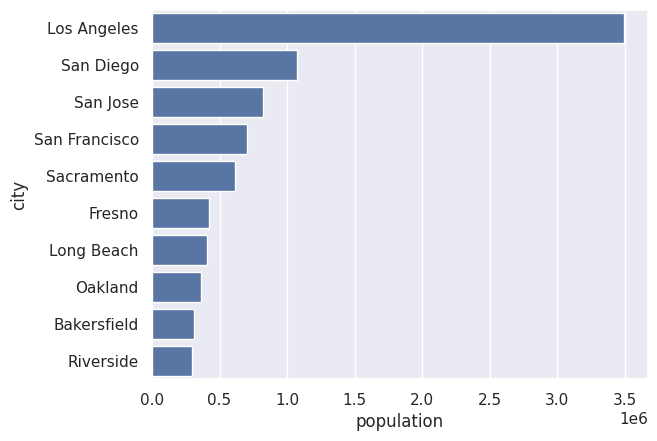

In [ ]:
sns.barplot(x='population', y='city', data=top10_largest_cities, color='b');

---

#### Exercise #5 — City frequencies with value_counts
CRISP-DM link: This falls under Data Understanding, where frequency counts help identify dominant categories (e.g., most common cities). Such insights guide later modelling, since imbalanced categories can bias results.

1. Find the top 5 cities by row count.

2. Compute the share of the dataset those cities represent.

3. Build a DataFrame with city, count, share.

---

In [123]:
# Find the top 5 cities by row count.
print('\033[1m' +  "\nFind the top 5 cities by row count." + '\033[0m')
top_5_cities = housing_merged['city'].value_counts().nlargest(5)
print(top_5_cities)

# Compute the share of the dataset those cities represent.
print('\033[1m' + "\nCompute the share of the dataset those cities represent." + '\033[0m')
total_rows = len(housing_merged)
city_shares = top_5_cities / total_rows
print(city_shares)

# Build a DataFrame with city, count, share.
print('\033[1m' + "\nBuild a DataFrame with city, count, share." + '\033[0m')
city_summary_df = pd.DataFrame({
    'count': top_5_cities,
    'share': city_shares
}).reset_index()
city_summary_df.columns = ['city', 'count', 'share'] # Renaming columns explicitly after reset_index
print(city_summary_df)


Find the top 5 cities by row count.
city
Los Angeles      2372
San Diego         809
San Francisco     574
San Jose          498
Sacramento        422
Name: count, dtype: int64

Compute the share of the dataset those cities represent.
city
Los Angeles      0.114922
San Diego        0.039196
San Francisco    0.027810
San Jose         0.024128
Sacramento       0.020446
Name: count, dtype: float64

Build a DataFrame with city, count, share.
            city  count     share
0    Los Angeles   2372  0.114922
1      San Diego    809  0.039196
2  San Francisco    574  0.027810
3       San Jose    498  0.024128
4     Sacramento    422  0.020446


## GroupBy mechanics

The group operation above can be best understood by the H. Wickam's [_split-apply-combine_](https://medium.com/analytics-vidhya/split-apply-combine-strategy-for-data-mining-4fd6e2a0cc99) strategy, where you break up a big problem into manageable pieces, operate on each piece independently and then put all the pieces back together.

**Split:**
In the first stage of the process, data contained in a `pandas.Series` or `pandas.DataFrame` object is _split_ into groups based on one or more specified _keys_. The splitting is performed on a particular _axis_ of the object (see the notebook from lesson 2). For example, a `pandas.DataFrame` can be grouped on its rows (`axis=0`) or its columns (`axis=1`).

**Apply:**
Once the split done, a function is _applied_ to each group, producing a new value.

**Combine:**
Finally, the results of all those function applications are _combined_ into a result object. The form of the resulting object will usualy depend on the what's being done to the data.

See the figure below for an example of a simple group aggregation.
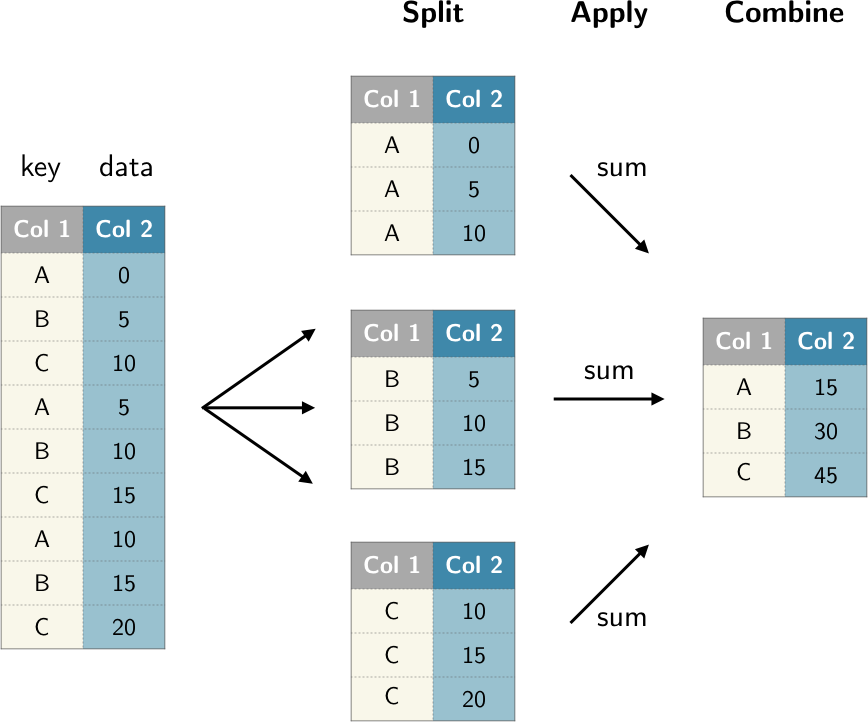

<b>Figure:</b> Illustraion of a group aggregation. </p>

In general, the grouping key can take many forms and the key do not have to be all of the same type. Frequently, the grouping information is found in the same `pandas.DataFrame` as the data you want to work on, so the key is usually a _column name_. For example let's create a simple `pandas.DataFrame` as follows:

In [ ]:
df_foo = pd.DataFrame(
    {
        "key1": ["a", "a", "b", "b", "a"],
        "key2": ["one", "two", "one", "two", "one"],
        "data1": np.random.randn(5),
        "data2": np.random.randn(5),
    }
)
df_foo

,key1,key2,data1,data2
0,a,one,1.389293,-0.342957
1,a,two,-0.774969,-0.403813
2,b,one,-0.709401,-1.035581
3,b,two,-0.260219,-0.594473
4,a,one,0.073256,-0.569116


We can then use the column names as the group keys (similar to what we did above with the beers):

In [ ]:
grouped = df_foo.groupby('key1'); grouped

This `grouped` variable is now a _GroupBy_ object. It has not actually calculated anything yet except for some intermediate data about the group key `df_foo['key1']`. The main idea is that this object has all of the information needed to then apply some operation to each of the groups. For example, we can get the mean per group as follows:

In [ ]:
df_grouped = grouped[['data1', 'data2']].mean(); df_grouped

,data1,data2
key1,,
a,0.229193,-0.438629
b,-0.484810,-0.815027


---

#### Exercise #6
CRISP-DM link: This spans Data Understanding (pattern exploration across cities) and Preparation (removing capped values). It illustrates how cleaning the data can change interpretations, reinforcing the iterative cycle of CRISP-DM.

1. Use the above `DataFrame.groupby()` techniques to find the top 10 cities which have the most expensive houses on average. Look up some of the names on the web - do the results make sense?
2. Use the `DataFrame.loc[]` method to filter out the houses with the capped values of over $500,000. Repeat the same step as above.

In [124]:
# Average median_house_value per city (descending), take top 10

# 1. Use the above DataFrame.groupby() techniques to find the top 10 cities which have the most expensive houses on average.
print('\033[1m' +  "Use the above DataFrame.groupby() techniques to find the top 10 cities which have the most expensive houses on average.." + '\033[0m')
top10_avg_price_all = housing_merged.groupby('city')['median_house_value'].mean().nlargest(10)
print(top10_avg_price_all)

# Do the results make sense?
'''
Yes, all ten cities are tied at exactly 500001, which is the dataset's cap, so the list is just alphabetical
order.
'''

# 2. Use the DataFrame.loc[] method to filter out the houses with the capped values of over $500,000. Repeat the same step as above.
print('\033[1m' +  "\nUse the DataFrame.loc[] method to filter out the houses with the capped values of over $500,000. Repeat the same step as above." + '\033[0m')
housing_uncapped = housing_merged.loc[housing_merged['median_house_value'] < 500001]
top10_avg_price_uncapped = housing_uncapped.groupby('city')['median_house_value'].mean().nlargest(10)
print(top10_avg_price_uncapped)

Use the above DataFrame.groupby() techniques to find the top 10 cities which have the most expensive houses on average..
city
Bell Canyon             500001.0
Bradbury                500001.0
Calabasas               500001.0
Hidden Hills            500001.0
Hillsborough            500001.0
Los Altos Hills         500001.0
Palos Verdes Estates    500001.0
Rolling Hills           500001.0
Ross                    500001.0
Summerland              500001.0
Name: median_house_value, dtype: float64

Use the DataFrame.loc[] method to filter out the houses with the capped values of over $500,000. Repeat the same step as above.
city
Emerald Hills       495900.000000
Montecito           463800.000000
Manhattan Beach     462200.000000
San Gregorio        456300.000000
Belvedere           441100.000000
Alamo               439060.000000
Topanga             437428.571429
Coto de Caza        436800.000000
Del Monte Forest    436260.000000
Monte Sereno        432100.000000
Name: median_house_value, dty

In [105]:
# Remove capped values (>= 500,000) using .loc[], then recompute top 10
housing_uncapped = housing_merged.loc[housing_merged['median_house_value'] < 500001]

# Group by city, calculate mean of median_house_value, and get top 10
top10_avg_price_uncapped_df = housing_uncapped.groupby('city')['median_house_value'].mean().nlargest(10).reset_index()
top10_avg_price_uncapped_df.columns = ['city', 'avg_price_uncapped']
print(top10_avg_price_uncapped_df)

               city  avg_price_uncapped
0     Emerald Hills       495900.000000
1         Montecito       463800.000000
2   Manhattan Beach       462200.000000
3      San Gregorio       456300.000000
4         Belvedere       441100.000000
5             Alamo       439060.000000
6           Topanga       437428.571429
7      Coto de Caza       436800.000000
8  Del Monte Forest       436260.000000
9      Monte Sereno       432100.000000


#### Exercise #7
CRISP-DM link: This fits into Data Understanding (examining house prices by proximity) and Evaluation (visualising whether the feature appears predictive). These insights may influence how you design models in the assignment.

1. Use the `DataFrame.groupby()` and `agg()` techniques to find the distribution of mean house prices according to `ocean_proximity`.
2. Store the result from the above step in a new `pandas.DataFrame` and visualise it with seaborn's barplot.

---

In [125]:
# Group by ocean_proximity and compute mean house price
mean_house_price_by_ocean_proximity = housing_merged.groupby('ocean_proximity').agg(mean_price=('median_house_value', 'mean')).reset_index()
print(mean_house_price_by_ocean_proximity)

  ocean_proximity     mean_price
0       <1H OCEAN  240084.285464
1          INLAND  124805.392001
2          ISLAND  380440.000000
3        NEAR BAY  259212.311790
4      NEAR OCEAN  249433.977427


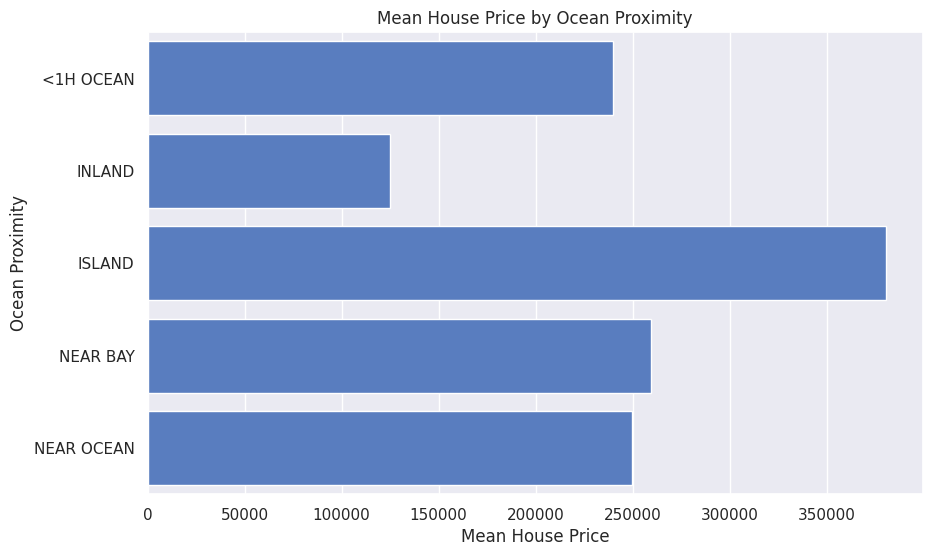

In [126]:
# Store the result from the above step in a new pandas.DataFrame and visualise it with seaborn's barplot.
plt.figure(figsize=(10, 6))
sns.barplot(x='mean_price', y='ocean_proximity', data=mean_house_price_by_ocean_proximity)
plt.title('Mean House Price by Ocean Proximity')
plt.xlabel('Mean House Price')
plt.ylabel('Ocean Proximity')
plt.show()